In [1]:
# Importando as bibliotecas
import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

# Configurando o visual dos gráficos
plt.style.use('seaborn-v0_8')
sns.set_palette('husl')

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
conn = pyodbc.connect(
    'DRIVER={ODBC Driver 17 for SQL Server};'
    'SERVER=localhost\\SQLEXPRESS;'
    'DATABASE=PeopleAnalytics;'
    'Trusted_Connection=yes;'
)

df = pd.read_sql('SELECT * FROM vw_analise_completa', conn)

print(f"Shape: {df.shape}")
print(f"\nColunas: {df.columns.tolist()}")
print(f"\nPrimeiras linhas:")
df.head()

Shape: (1470, 26)

Colunas: ['id_funcionario', 'genero', 'estado_civil', 'idade', 'departamento', 'cargo', 'area_educacao', 'satisfacao_trabalho', 'satisfacao_ambiente', 'satisfacao_relacionamento', 'equilibrio_vida', 'anos_empresa', 'anos_cargo_atual', 'anos_ultima_promocao', 'anos_gestor_atual', 'salario_mensal', 'percentual_aumento', 'acoes_empresa', 'horas_extra', 'viagens_negocios', 'attrition', 'distancia_casa', 'nivel_cargo', 'empresas_anteriores', 'score_risco', 'classificacao_risco']

Primeiras linhas:


C:\Users\joaop\AppData\Local\Temp\ipykernel_24184\730502178.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql('SELECT * FROM vw_analise_completa', conn)


,id_funcionario,genero,estado_civil,idade,departamento,cargo,area_educacao,satisfacao_trabalho,satisfacao_ambiente,satisfacao_relacionamento,...,percentual_aumento,acoes_empresa,horas_extra,viagens_negocios,attrition,distancia_casa,nivel_cargo,empresas_anteriores,score_risco,classificacao_risco
0,1,Female,Single,41,Sales,Sales Executive,Life Sciences,4,2,1,...,11,0,Yes,Travel_Rarely,Yes,1,2,8,4,Médio Risco
1,2,Male,Married,49,Research & Development,Research Scientist,Life Sciences,2,3,4,...,23,1,No,Travel_Frequently,No,8,2,1,2,Baixo Risco
2,4,Male,Single,37,Research & Development,Laboratory Technician,Other,3,4,2,...,15,0,Yes,Travel_Rarely,Yes,2,1,6,4,Médio Risco
3,5,Female,Married,33,Research & Development,Research Scientist,Life Sciences,3,4,3,...,11,0,Yes,Travel_Frequently,No,3,1,1,3,Médio Risco
4,7,Male,Married,27,Research & Development,Laboratory Technician,Medical,2,1,4,...,12,1,No,Travel_Rarely,No,2,1,9,2,Baixo Risco


In [3]:
# Visão geral do dataset
print("=== INFORMAÇÕES GERAIS ===")
print(f"Total de funcionários: {len(df)}")
print(f"Total de colunas: {len(df.columns)}")

print("\n=== TIPOS DE DADOS ===")
print(df.dtypes)

print("\n=== VALORES NULOS ===")
print(df.isnull().sum())

print("\n=== ESTATÍSTICAS DESCRITIVAS ===")
df.describe()

=== INFORMAÇÕES GERAIS ===
Total de funcionários: 1470
Total de colunas: 26

=== TIPOS DE DADOS ===
id_funcionario                int64
genero                       object
estado_civil                 object
idade                         int64
departamento                 object
cargo                        object
area_educacao                object
satisfacao_trabalho           int64
satisfacao_ambiente           int64
satisfacao_relacionamento     int64
equilibrio_vida               int64
anos_empresa                  int64
anos_cargo_atual              int64
anos_ultima_promocao          int64
anos_gestor_atual             int64
salario_mensal                int64
percentual_aumento            int64
acoes_empresa                 int64
horas_extra                  object
viagens_negocios             object
attrition                    object
distancia_casa                int64
nivel_cargo                   int64
empresas_anteriores           int64
score_risco                   int64


,id_funcionario,idade,satisfacao_trabalho,satisfacao_ambiente,satisfacao_relacionamento,equilibrio_vida,anos_empresa,anos_cargo_atual,anos_ultima_promocao,anos_gestor_atual,salario_mensal,percentual_aumento,acoes_empresa,distancia_casa,nivel_cargo,empresas_anteriores,score_risco
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,1024.865306,36.923810,2.728571,2.721769,2.712245,2.761224,7.008163,4.229252,2.187755,4.123129,6502.931293,15.209524,0.793878,9.192517,2.063946,2.693197,2.470748
std,602.024335,9.135373,1.102846,1.093082,1.081209,0.706476,6.126525,3.623137,3.222430,3.568136,4707.956783,3.659938,0.852077,8.106864,1.106940,2.498009,1.756490
min,1.000000,18.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1009.000000,11.000000,0.000000,1.000000,1.000000,0.000000,0.000000
25%,491.250000,30.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,2911.000000,12.000000,0.000000,2.000000,1.000000,1.000000,1.000000
50%,1020.500000,36.000000,3.000000,3.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,4919.000000,14.000000,1.000000,7.000000,2.000000,2.000000,2.000000
75%,1555.750000,43.000000,4.000000,4.000000,4.000000,3.000000,9.000000,7.000000,3.000000,7.000000,8379.000000,18.000000,1.000000,14.000000,3.000000,4.000000,4.000000
max,2068.000000,60.000000,4.000000,4.000000,4.000000,4.000000,40.000000,18.000000,15.000000,17.000000,19999.000000,25.000000,3.000000,29.000000,5.000000,9.000000,8.000000


=== DISTRIBUIÇÃO DO TURNOVER ===
attrition
No     1233
Yes     237
Name: count, dtype: int64

Taxa de turnover: 16.1%


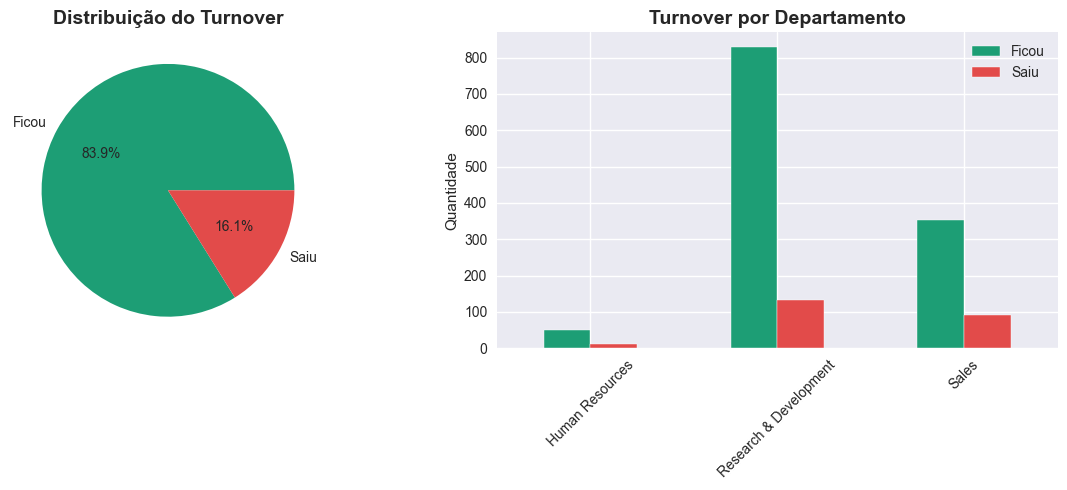

In [4]:
# Análise do Attrition
print("=== DISTRIBUIÇÃO DO TURNOVER ===")
print(df['attrition'].value_counts())
print(f"\nTaxa de turnover: {df['attrition'].value_counts(normalize=True)['Yes']*100:.1f}%")

# Gráfico
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pizza
df['attrition'].value_counts().plot(
    kind='pie', 
    ax=axes[0],
    autopct='%1.1f%%',
    colors=['#1D9E75', '#E24B4A'],
    labels=['Ficou', 'Saiu']
)
axes[0].set_title('Distribuição do Turnover', fontsize=14, fontweight='bold')
axes[0].set_ylabel('')

# Barras por departamento
turnover_depto = df.groupby(['departamento', 'attrition']).size().unstack()
turnover_depto.plot(
    kind='bar',
    ax=axes[1],
    color=['#1D9E75', '#E24B4A'],
    edgecolor='white'
)
axes[1].set_title('Turnover por Departamento', fontsize=14, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('Quantidade')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(['Ficou', 'Saiu'])

plt.tight_layout()
plt.show()

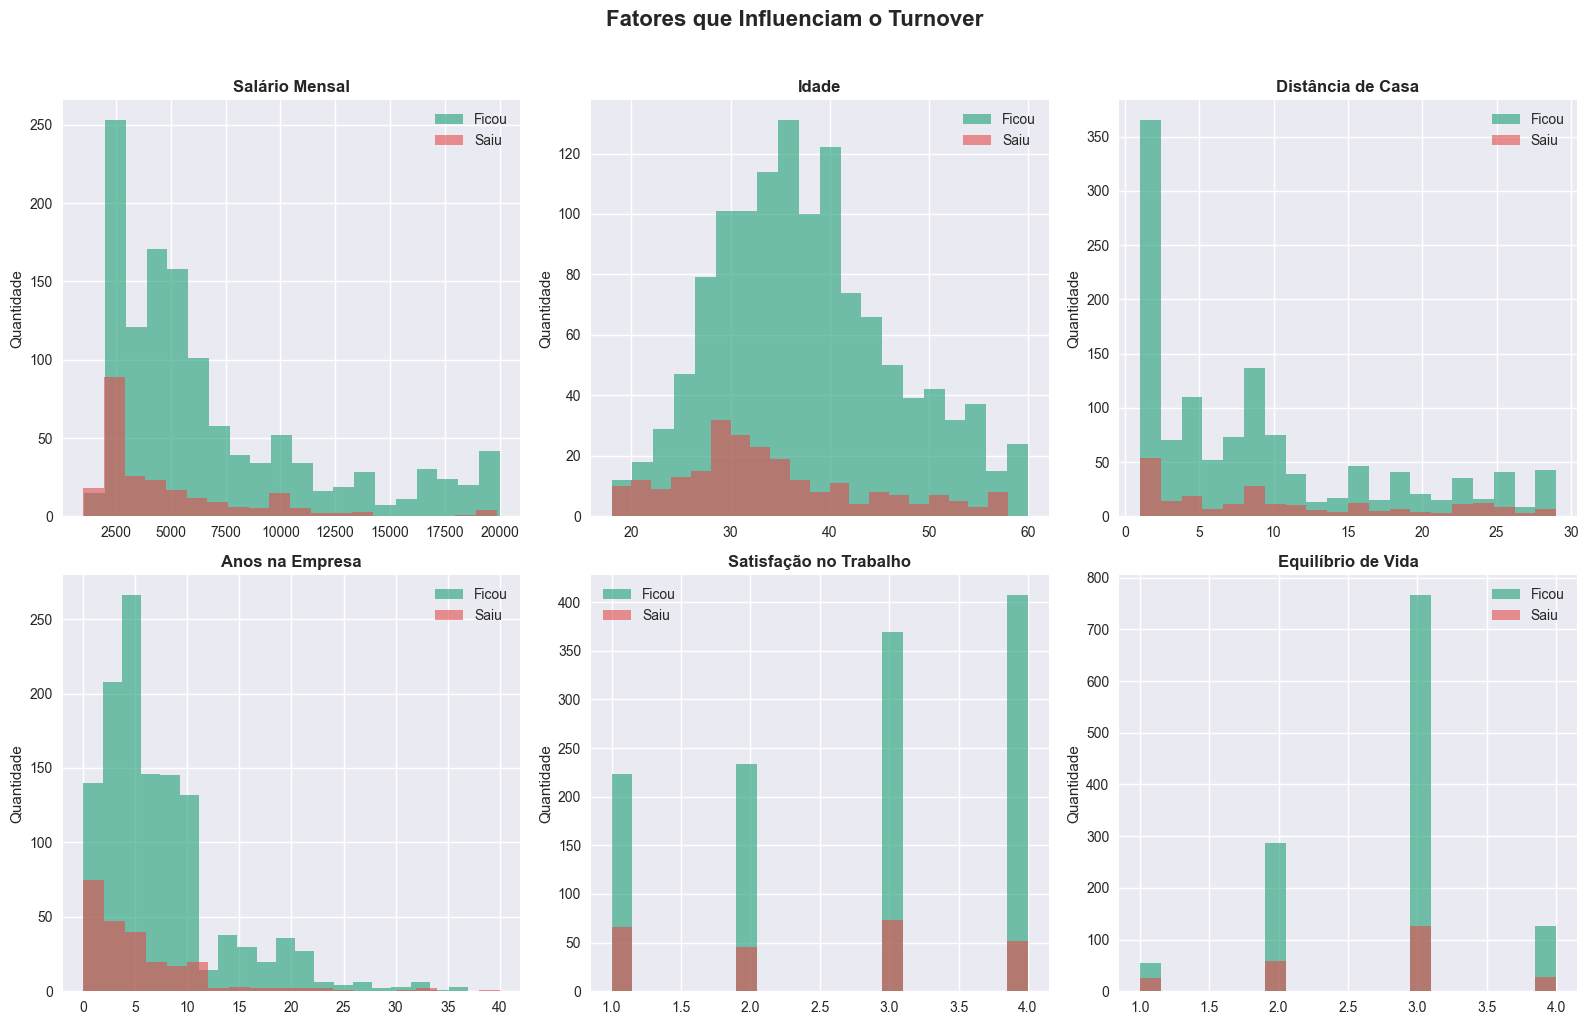

=== MÉDIAS COMPARATIVAS: FICOU vs SAIU ===
salario_mensal            | Ficou:  6832.7 | Saiu:  4787.1
idade                     | Ficou:    37.6 | Saiu:    33.6
distancia_casa            | Ficou:     8.9 | Saiu:    10.6
anos_empresa              | Ficou:     7.4 | Saiu:     5.1
satisfacao_trabalho       | Ficou:     2.8 | Saiu:     2.5
equilibrio_vida           | Ficou:     2.8 | Saiu:     2.7


In [5]:
# Análise de fatores numéricos vs Attrition
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

fatores = ['salario_mensal', 'idade', 'distancia_casa', 
           'anos_empresa', 'satisfacao_trabalho', 'equilibrio_vida']

titulos = ['Salário Mensal', 'Idade', 'Distância de Casa',
           'Anos na Empresa', 'Satisfação no Trabalho', 'Equilíbrio de Vida']

for i, (fator, titulo) in enumerate(zip(fatores, titulos)):
    ficou = df[df['attrition'] == 'No'][fator]
    saiu = df[df['attrition'] == 'Yes'][fator]
    
    axes[i].hist(ficou, alpha=0.6, color='#1D9E75', label='Ficou', bins=20)
    axes[i].hist(saiu, alpha=0.6, color='#E24B4A', label='Saiu', bins=20)
    axes[i].set_title(titulo, fontsize=12, fontweight='bold')
    axes[i].legend()
    axes[i].set_ylabel('Quantidade')

plt.suptitle('Fatores que Influenciam o Turnover', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Médias comparativas
print("=== MÉDIAS COMPARATIVAS: FICOU vs SAIU ===")
metricas = ['salario_mensal', 'idade', 'distancia_casa', 
            'anos_empresa', 'satisfacao_trabalho', 'equilibrio_vida']

for m in metricas:
    media_ficou = df[df['attrition'] == 'No'][m].mean()
    media_saiu = df[df['attrition'] == 'Yes'][m].mean()
    print(f"{m:25s} | Ficou: {media_ficou:7.1f} | Saiu: {media_saiu:7.1f}")

In [7]:
# Interpretando os insights
print("=== INSIGHTS DO DATASET IBM HR ===")
print()
print(" PERFIL DE QUEM SAI:")
print(f"  • Salário médio R$ 4.787 vs R$ 6.832 de quem fica — 30% menor")
print(f"  • Idade média 33.6 anos vs 37.6 — funcionários mais jovens saem mais")
print(f"  • Mora mais longe — 10.6km vs 8.9km de distância")
print(f"  • Menos tempo na empresa — 5.1 anos vs 7.4 anos")
print(f"  • Satisfação levemente menor em todos os indicadores")
print()
print(" PRINCIPAIS FATORES DE RISCO:")
print(f"  1. SALÁRIO — maior diferença proporcional (30%)")
print(f"  2. TEMPO NA EMPRESA — quem sai tem menos vínculo")
print(f"  3. IDADE — jovens têm mais mobilidade")
print(f"  4. DISTÂNCIA — impacto no dia a dia")

=== INSIGHTS DO DATASET IBM HR ===

 PERFIL DE QUEM SAI:
  • Salário médio R$ 4.787 vs R$ 6.832 de quem fica — 30% menor
  • Idade média 33.6 anos vs 37.6 — funcionários mais jovens saem mais
  • Mora mais longe — 10.6km vs 8.9km de distância
  • Menos tempo na empresa — 5.1 anos vs 7.4 anos
  • Satisfação levemente menor em todos os indicadores

 PRINCIPAIS FATORES DE RISCO:
  1. SALÁRIO — maior diferença proporcional (30%)
  2. TEMPO NA EMPRESA — quem sai tem menos vínculo
  3. IDADE — jovens têm mais mobilidade
  4. DISTÂNCIA — impacto no dia a dia


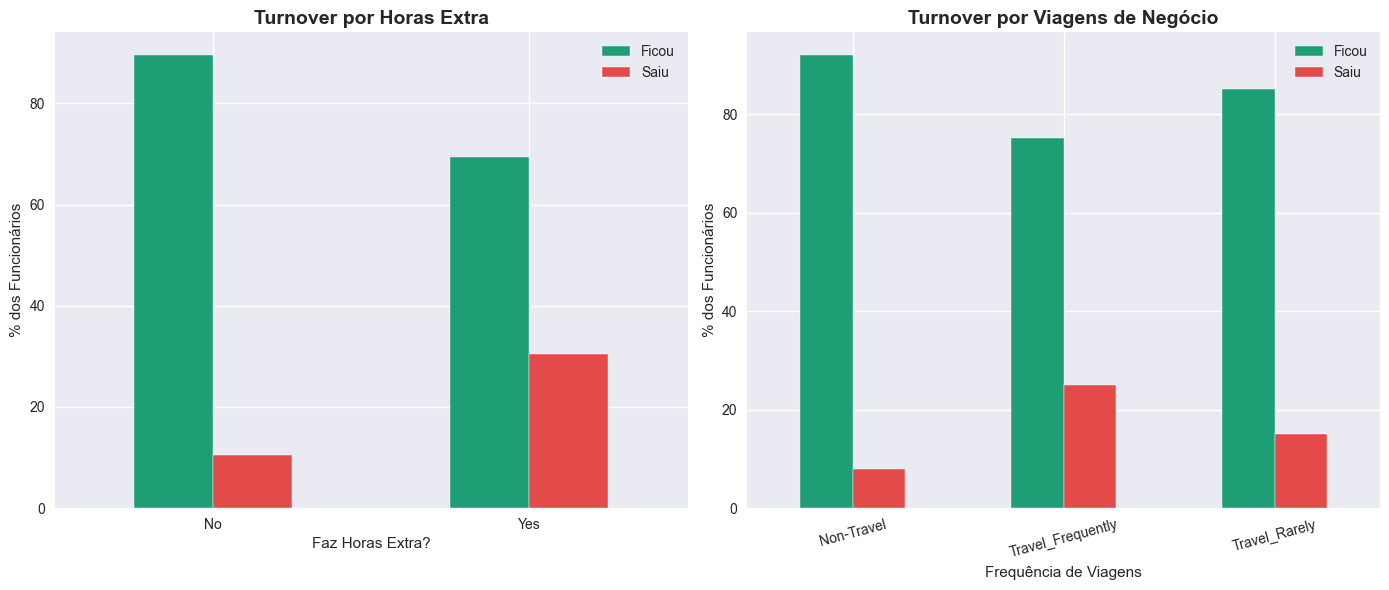

=== TAXA DE SAÍDA POR HORAS EXTRA ===
  No: 10.4% de turnover
  Yes: 30.5% de turnover

=== TAXA DE SAÍDA POR VIAGENS ===
  Non-Travel: 8.0% de turnover
  Travel_Frequently: 24.9% de turnover
  Travel_Rarely: 15.0% de turnover


In [8]:
# Análise de horas extra e viagens
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Horas extra vs Attrition
horas_extra = df.groupby(['horas_extra', 'attrition']).size().unstack(fill_value=0)
horas_extra_pct = horas_extra.div(horas_extra.sum(axis=1), axis=0) * 100
horas_extra_pct.plot(
    kind='bar',
    ax=axes[0],
    color=['#1D9E75', '#E24B4A'],
    edgecolor='white'
)
axes[0].set_title('Turnover por Horas Extra', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Faz Horas Extra?')
axes[0].set_ylabel('% dos Funcionários')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(['Ficou', 'Saiu'])

# Viagens vs Attrition
viagens = df.groupby(['viagens_negocios', 'attrition']).size().unstack(fill_value=0)
viagens_pct = viagens.div(viagens.sum(axis=1), axis=0) * 100
viagens_pct.plot(
    kind='bar',
    ax=axes[1],
    color=['#1D9E75', '#E24B4A'],
    edgecolor='white'
)
axes[1].set_title('Turnover por Viagens de Negócio', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Frequência de Viagens')
axes[1].set_ylabel('% dos Funcionários')
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(['Ficou', 'Saiu'])

plt.tight_layout()
plt.show()

# Números exatos
print("=== TAXA DE SAÍDA POR HORAS EXTRA ===")
for grupo, dados in df.groupby('horas_extra'):
    taxa = (dados['attrition'] == 'Yes').mean() * 100
    print(f"  {grupo}: {taxa:.1f}% de turnover")

print("\n=== TAXA DE SAÍDA POR VIAGENS ===")
for grupo, dados in df.groupby('viagens_negocios'):
    taxa = (dados['attrition'] == 'Yes').mean() * 100
    print(f"  {grupo}: {taxa:.1f}% de turnover")

In [9]:
# Resumo dos insights mais impactantes
print("=== DESCOBERTAS MAIS IMPORTANTES ===")
print()
print("  HORAS EXTRA:")
print(f"  Quem faz horas extra tem turnover de 30.5%")
print(f"  Quem não faz tem apenas 10.4%")
print(f"  → Horas extra TRIPLICAM a chance de saída!")
print()
print("  VIAGENS FREQUENTES:")
print(f"  Quem viaja frequentemente: 24.9% de turnover")
print(f"  Quem raramente viaja: 15.0%")
print(f"  Quem não viaja: apenas 8.0%")
print(f"  → Viagens frequentes TRIPLICAM a chance de saída!")
print()
print(" CONCLUSÃO:")
print(f"  Funcionário que faz horas extra + viaja muito")
print(f"  é o perfil de MAIOR risco de turnover na empresa.")

=== DESCOBERTAS MAIS IMPORTANTES ===

  HORAS EXTRA:
  Quem faz horas extra tem turnover de 30.5%
  Quem não faz tem apenas 10.4%
  → Horas extra TRIPLICAM a chance de saída!

  VIAGENS FREQUENTES:
  Quem viaja frequentemente: 24.9% de turnover
  Quem raramente viaja: 15.0%
  Quem não viaja: apenas 8.0%
  → Viagens frequentes TRIPLICAM a chance de saída!

 CONCLUSÃO:
  Funcionário que faz horas extra + viaja muito
  é o perfil de MAIOR risco de turnover na empresa.


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Preparando os dados para o modelo
print("=== PREPARANDO DADOS PARA O MODELO ===")

# Selecionando features relevantes
features = [
    'salario_mensal', 'idade', 'distancia_casa', 'anos_empresa',
    'satisfacao_trabalho', 'equilibrio_vida', 'satisfacao_ambiente',
    'satisfacao_relacionamento', 'anos_ultima_promocao', 'anos_gestor_atual',
    'nivel_cargo', 'empresas_anteriores', 'percentual_aumento',
    'horas_extra', 'viagens_negocios', 'genero', 'estado_civil'
]

df_modelo = df[features + ['attrition']].copy()

# Convertendo colunas categóricas para número
le = LabelEncoder()
colunas_categoricas = ['horas_extra', 'viagens_negocios', 'genero', 'estado_civil']

for col in colunas_categoricas:
    df_modelo[col] = le.fit_transform(df_modelo[col])

# Separando X (features) e y (target)
X = df_modelo[features]
y = (df_modelo['attrition'] == 'Yes').astype(int)

print(f"Features: {X.shape[1]} colunas")
print(f"Amostras: {X.shape[0]} funcionários")
print(f"Turnover (1=Saiu, 0=Ficou):\n{y.value_counts()}")

=== PREPARANDO DADOS PARA O MODELO ===
Features: 17 colunas
Amostras: 1470 funcionários
Turnover (1=Saiu, 0=Ficou):
attrition
0    1233
1     237
Name: count, dtype: int64


In [11]:
# Dividindo em treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]} funcionários")
print(f"Teste: {X_test.shape[0]} funcionários")

# Treinando o modelo Random Forest
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

modelo.fit(X_train, y_train)

# Avaliando o modelo
y_pred = modelo.predict(X_test)

print("\n=== RESULTADO DO MODELO ===")
print(f"Acurácia: {accuracy_score(y_test, y_pred)*100:.1f}%")
print()
print("=== RELATÓRIO COMPLETO ===")
print(classification_report(y_test, y_pred, target_names=['Ficou', 'Saiu']))

Treino: 1176 funcionários
Teste: 294 funcionários

=== RESULTADO DO MODELO ===
Acurácia: 81.3%

=== RELATÓRIO COMPLETO ===
              precision    recall  f1-score   support

       Ficou       0.87      0.92      0.89       247
        Saiu       0.38      0.26      0.30        47

    accuracy                           0.81       294
   macro avg       0.62      0.59      0.60       294
weighted avg       0.79      0.81      0.80       294



=== INTERPRETANDO OS RESULTADOS ===

 O modelo acerta 81.3% dos casos no geral

  PROBLEMA — Desbalanceamento de classes:
  • Ficou: precision 87%, recall 92% — modelo muito bom
  • Saiu:  precision 38%, recall 26% — modelo fraco aqui

 Por que isso acontece?
  No dataset temos 1233 que ficaram vs 237 que saíram
  O modelo 'aprende' mais com quem ficou pq tem mais dados
  Resultado: bom em prever quem fica, ruim em prever quem sai

 O que importa pra RH:
  Em People Analytics o RECALL de 'Saiu' é o mais crítico
  Preferimos errar e alertar alguém que vai ficar
  do que deixar passar alguém que vai sair sem avisar


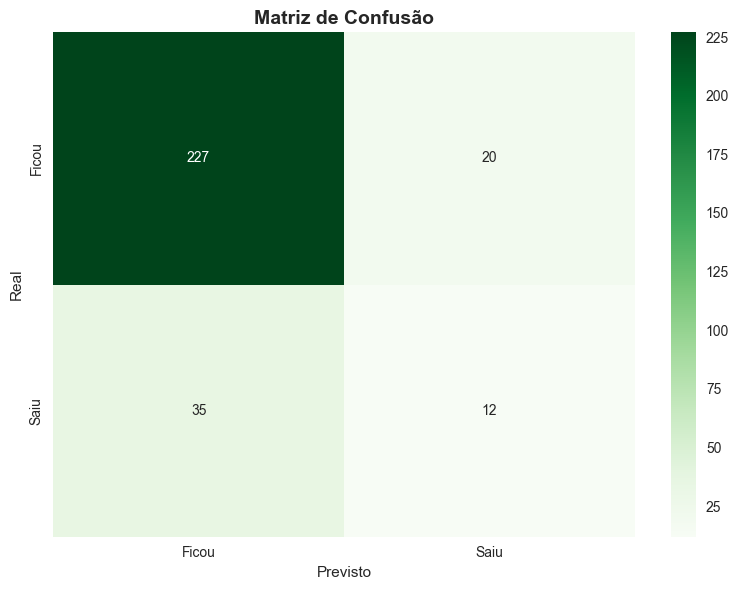

In [13]:
# Analisando o resultado
print("=== INTERPRETANDO OS RESULTADOS ===")
print()
print(" O modelo acerta 81.3% dos casos no geral")
print()
print("  PROBLEMA — Desbalanceamento de classes:")
print(f"  • Ficou: precision 87%, recall 92% — modelo muito bom")
print(f"  • Saiu:  precision 38%, recall 26% — modelo fraco aqui")
print()
print(" Por que isso acontece?")
print("  No dataset temos 1233 que ficaram vs 237 que saíram")
print("  O modelo 'aprende' mais com quem ficou pq tem mais dados")
print("  Resultado: bom em prever quem fica, ruim em prever quem sai")
print()
print(" O que importa pra RH:")
print("  Em People Analytics o RECALL de 'Saiu' é o mais crítico")
print("  Preferimos errar e alertar alguém que vai ficar")
print("  do que deixar passar alguém que vai sair sem avisar")

# Matriz de confusão
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Greens',
    xticklabels=['Ficou', 'Saiu'],
    yticklabels=['Ficou', 'Saiu'],
    ax=ax
)
ax.set_title('Matriz de Confusão', fontsize=14, fontweight='bold')
ax.set_ylabel('Real')
ax.set_xlabel('Previsto')
plt.tight_layout()
plt.show()

In [14]:
# Interpretando a matriz de confusão
print("=== LENDO A MATRIZ DE CONFUSÃO ===")
print()
print("                 PREVISTO")
print("              Ficou  |  Saiu")
print("REAL  Ficou |  227   |   20  |")
print("      Saiu  |   35   |   12  |")
print()
print(" O que cada número significa:")
print()
print("   227 — Acertou: previu que ficaria e ficou (Verdadeiro Negativo)")
print("    12 — Acertou: previu que sairia e saiu  (Verdadeiro Positivo)")
print()
print("    20 — Errou: previu que sairia mas ficou (Falso Positivo)")
print("         → RH investigaria desnecessariamente")
print()
print("   35 — Errou: previu que ficaria mas saiu (Falso Negativo)")
print("         → PIOR ERRO: não alertou e o funcionário saiu!")
print()
print(" De 47 funcionários que saíram de verdade:")
print(f"  O modelo identificou apenas 12 ({12/47*100:.0f}%)")
print(f"  Deixou passar 35 ({35/47*100:.0f}%) sem alertar")

=== LENDO A MATRIZ DE CONFUSÃO ===

                 PREVISTO
              Ficou  |  Saiu
REAL  Ficou |  227   |   20  |
      Saiu  |   35   |   12  |

 O que cada número significa:

   227 — Acertou: previu que ficaria e ficou (Verdadeiro Negativo)
    12 — Acertou: previu que sairia e saiu  (Verdadeiro Positivo)

    20 — Errou: previu que sairia mas ficou (Falso Positivo)
         → RH investigaria desnecessariamente

   35 — Errou: previu que ficaria mas saiu (Falso Negativo)
         → PIOR ERRO: não alertou e o funcionário saiu!

 De 47 funcionários que saíram de verdade:
  O modelo identificou apenas 12 (26%)
  Deixou passar 35 (74%) sem alertar


=== TOP 10 FATORES QUE MAIS INFLUENCIAM O TURNOVER ===

  salario_mensal                 ████████████ 12.2%
  idade                          ███████████ 11.5%
  anos_empresa                   ████████ 8.8%
  distancia_casa                 ████████ 8.1%
  percentual_aumento             ██████ 6.7%
  anos_gestor_atual              ██████ 6.6%
  empresas_anteriores            ██████ 6.5%
  horas_extra                    ██████ 6.0%
  satisfacao_ambiente            ████ 4.7%
  estado_civil                   ████ 4.5%


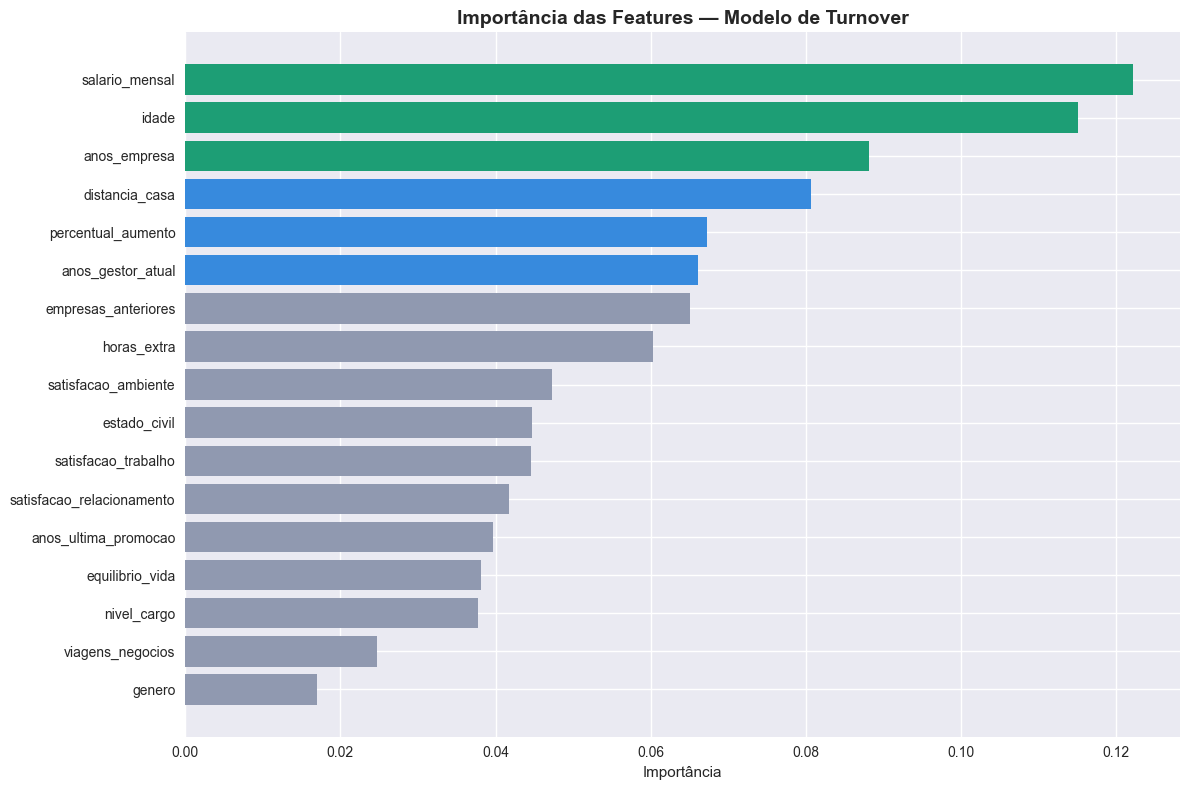

In [15]:
# Importância das features
importancias = pd.DataFrame({
    'feature': features,
    'importancia': modelo.feature_importances_
}).sort_values('importancia', ascending=False)

print("=== TOP 10 FATORES QUE MAIS INFLUENCIAM O TURNOVER ===")
print()
for i, row in importancias.head(10).iterrows():
    barra = '█' * int(row['importancia'] * 100)
    print(f"  {row['feature']:30s} {barra} {row['importancia']*100:.1f}%")

# Gráfico
fig, ax = plt.subplots(figsize=(12, 8))
cores = ['#1D9E75' if i < 3 else '#378ADD' if i < 6 else '#9099B0' 
         for i in range(len(importancias))]

ax.barh(importancias['feature'], importancias['importancia'], color=cores)
ax.set_title('Importância das Features — Modelo de Turnover', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Importância')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [17]:
# Resumo final dos insights
print("=== CONCLUSÕES FINAIS DO MODELO ===")
print()
print(" TOP 3 FATORES DE RISCO DE TURNOVER:")
print()
print("  1. SALÁRIO (12.2%) — fator mais importante")
print("     Funcionários com salário baixo têm 30% mais chance de sair")
print()
print("  2. IDADE (11.5%) — segundo mais importante")  
print("     Funcionários mais jovens têm muito mais mobilidade")
print()
print("  3. ANOS NA EMPRESA (8.8%) — vínculo importa")
print("     Quanto menos tempo, maior o risco de saída")
print()
print(" OUTROS FATORES RELEVANTES:")
print("  • Distância de casa (8.1%) — impacto diário no funcionário")
print("  • Percentual de aumento (6.7%) — reconhecimento financeiro")
print("  • Tempo com mesmo gestor (6.6%) — relacionamento importa")
print("  • Empresas anteriores (6.5%) — histórico de mobilidade")
print("  • Horas extra (6.0%) — desgaste operacional")
print()
print(" RECOMENDAÇÃO ESTRATÉGICA DE RH:")
print("  Funcionário jovem + salário baixo + faz horas extra")
print("  = perfil de ALTÍSSIMO risco — prioridade de retenção!")

=== CONCLUSÕES FINAIS DO MODELO ===

 TOP 3 FATORES DE RISCO DE TURNOVER:

  1. SALÁRIO (12.2%) — fator mais importante
     Funcionários com salário baixo têm 30% mais chance de sair

  2. IDADE (11.5%) — segundo mais importante
     Funcionários mais jovens têm muito mais mobilidade

  3. ANOS NA EMPRESA (8.8%) — vínculo importa
     Quanto menos tempo, maior o risco de saída

 OUTROS FATORES RELEVANTES:
  • Distância de casa (8.1%) — impacto diário no funcionário
  • Percentual de aumento (6.7%) — reconhecimento financeiro
  • Tempo com mesmo gestor (6.6%) — relacionamento importa
  • Empresas anteriores (6.5%) — histórico de mobilidade
  • Horas extra (6.0%) — desgaste operacional

 RECOMENDAÇÃO ESTRATÉGICA DE RH:
  Funcionário jovem + salário baixo + faz horas extra
  = perfil de ALTÍSSIMO risco — prioridade de retenção!
